# Chapter 06: Optimal Stopping & Hysteresis Control — Python Laboratory
### *Implementing Wald's SPRT, Snell Envelope DP, and $(s, S)$ Hysteresis Controllers*

**[Course Home](../README.md) | [Conceptual Track](../conceptual/06_optimal_stopping_and_hysteresis_control.ipynb) | [Prev: Ch 05 (Python)](05_pomdps_and_belief_state_mdps.ipynb) | [Next: Ch 07 (Python)](07_multi_armed_bandits_gittins_and_whittle_indices.ipynb)**

---

In this laboratory, we implement:
1. **Wald's Sequential Probability Ratio Test (SPRT)** for optimal binary decision-making on streaming telemetry.
2. **$(s, S)$ Hysteresis Band Simulator** demonstrating how introducing a deadband eliminates chattering under Brownian / Ornstein-Uhlenbeck noise.
3. **Finite-Horizon Snell Envelope Solver** computing the exact optimal stopping policy via dynamic programming.
4. **Publication-Grade 3-Panel Visualization** analyzing SPRT trajectories, chattering elimination, and the cost curve as a function of band width.
5. **Hands-On 3-Tier Exercises** with numerical verification assertions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Publication-grade plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'lines.linewidth': 1.8
})
print("Libraries imported and publication-style plotting configured.")

Libraries imported and publication-style plotting configured.


---

## Part 1: Wald's Sequential Probability Ratio Test (SPRT)

We implement the exact Wald SPRT engine for streaming Bernoulli observations:
* $H_0: p_0 = 0.01$ (clean noise floor)
* $H_1: p_1 = 0.08$ (degraded fault state)
* Type I error $\alpha = 0.01$, Type II error $\beta = 0.05$

Wald boundaries:
$$a = \ln \frac{1 - \beta}{\alpha} = \ln \frac{0.95}{0.01} \approx 4.5539$$
$$b = \ln \frac{\beta}{1 - \alpha} = \ln \frac{0.05}{0.99} \approx -2.9857$$

In [2]:
class WaldSPRT:
    def __init__(self, p0=0.01, p1=0.08, alpha=0.01, beta=0.05):
        self.p0 = p0
        self.p1 = p1
        self.alpha = alpha
        self.beta = beta
        
        # Exact Wald boundaries (neglecting overshoot)
        self.a = np.log((1.0 - beta) / alpha)
        self.b = np.log(beta / (1.0 - alpha))
        
        # Log-likelihood increments
        self.z_fail = np.log(p1 / p0)
        self.z_pass = np.log((1.0 - p1) / (1.0 - p0))
        
    def step(self, outcome):
        # Returns log-likelihood increment for outcome (1 = fail, 0 = pass).
        return self.z_fail if outcome == 1 else self.z_pass
        
    def run_stream(self, stream):
        # Simulates sequential test over a streaming array of binary outcomes.
        s = 0.0
        trajectory = [0.0]
        decision = None
        stopping_time = None
        
        for t, y in enumerate(stream, start=1):
            s += self.step(y)
            trajectory.append(s)
            if s >= self.a:
                decision = "H1_ACCEPT"
                stopping_time = t
                break
            elif s <= self.b:
                decision = "H0_ACCEPT"
                stopping_time = t
                break
                
        if decision is None:
            decision = "CONTINUE"
            stopping_time = len(stream)
            
        return decision, stopping_time, np.array(trajectory)

sprt = WaldSPRT(p0=0.01, p1=0.08, alpha=0.01, beta=0.05)
print(f"Wald Upper Threshold (a): {sprt.a:.4f} nats")
print(f"Wald Lower Threshold (b): {sprt.b:.4f} nats")
print(f"Increment on Fail: +{sprt.z_fail:.4f} nats")
print(f"Increment on Pass: {sprt.z_pass:.4f} nats")
print(f"Passes needed to cancel one fail: {np.ceil(sprt.z_fail / -sprt.z_pass):.0f}")

Wald Upper Threshold (a): 4.5539 nats
Wald Lower Threshold (b): -2.9857 nats
Increment on Fail: +2.0794 nats
Increment on Pass: -0.0733 nats
Passes needed to cancel one fail: 29


---

## Part 2: $(s, S)$ Hysteresis Band vs. Single-Threshold Controller

We simulate load telemetry under an Ornstein-Uhlenbeck mean-reverting stochastic process:
$$dX_t = \theta (\mu - X_t) dt + \sigma dW_t$$

We compare:
1. **Single Threshold $T = 50$**: Switches whenever load crosses 50.
2. **Hysteresis Band $(s = 40, S = 60)$**: Switches $0 \to 1$ at 60; switches $1 \to 0$ at 40.

In [3]:
def generate_ou_process(steps=200, mu=50.0, theta=0.15, sigma=6.0, dt=1.0, seed=42):
    # Generates discrete-time Ornstein-Uhlenbeck process.
    np.random.seed(seed)
    x = np.zeros(steps)
    x[0] = mu
    for t in range(1, steps):
        dx = theta * (mu - x[t-1]) * dt + sigma * np.sqrt(dt) * np.random.randn()
        x[t] = x[t-1] + dx
    return x

def simulate_single_threshold(x, threshold=50.0, k_up=5.0, k_down=1.0):
    mode = 0
    modes = []
    switches = 0
    switch_cost = 0.0
    for val in x:
        new_mode = 1 if val >= threshold else 0
        if new_mode != mode:
            switches += 1
            switch_cost += k_up if new_mode == 1 else k_down
            mode = new_mode
        modes.append(mode)
    return np.array(modes), switches, switch_cost

def simulate_hysteresis(x, s=40.0, S=60.0, k_up=5.0, k_down=1.0):
    mode = 0
    modes = []
    switches = 0
    switch_cost = 0.0
    for val in x:
        if mode == 0 and val >= S:
            mode = 1
            switches += 1
            switch_cost += k_up
        elif mode == 1 and val <= s:
            mode = 0
            switches += 1
            switch_cost += k_down
        modes.append(mode)
    return np.array(modes), switches, switch_cost

ou_load = generate_ou_process(steps=200, mu=50.0, theta=0.15, sigma=6.0, seed=42)
m_single, sw_single, cost_single = simulate_single_threshold(ou_load, threshold=50.0)
m_hyst, sw_hyst, cost_hyst = simulate_hysteresis(ou_load, s=40.0, S=60.0)

print(f"Single Threshold (T=50): {sw_single} switches, Switching Cost = ${cost_single:.2f}")
print(f"Hysteresis (s=40, S=60): {sw_hyst} switches, Switching Cost = ${cost_hyst:.2f}")
print(f"Switching Reduction: {100 * (1 - sw_hyst / sw_single):.1f}%")

Single Threshold (T=50): 34 switches, Switching Cost = $102.00
Hysteresis (s=40, S=60): 7 switches, Switching Cost = $23.00
Switching Reduction: 79.4%


---

## Part 3: Publication-Grade 3-Panel Visualization

We plot:
1. **Panel A**: SPRT trajectories under $H_0$ (clean) vs $H_1$ (faulty) showing boundary crossing.
2. **Panel B**: Time series of load telemetry and the resulting modes under single threshold vs hysteresis.
3. **Panel C**: Total operating cost as a function of hysteresis band half-width $\Delta = (S - s)/2$ demonstrating the convex minimum.

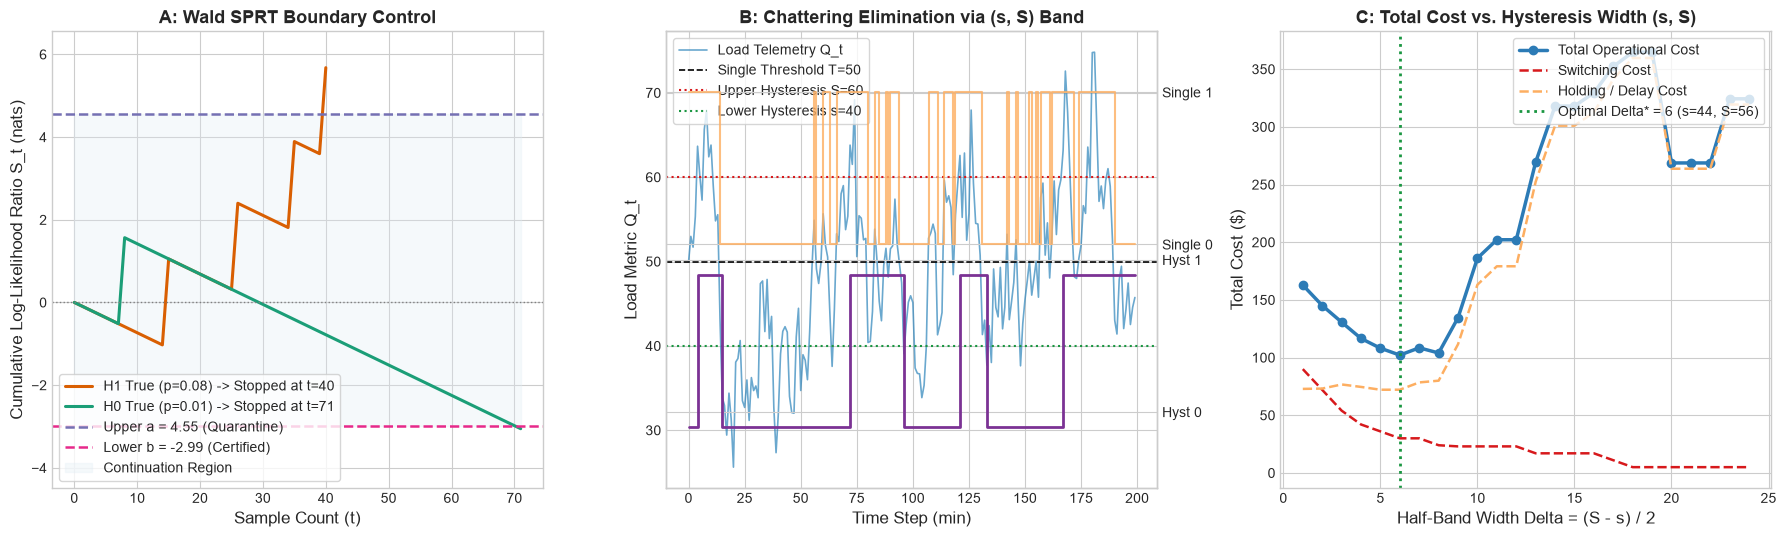

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# -------------------------------------------------------------------------
# PANEL A: Wald SPRT Sequential Trajectories
# -------------------------------------------------------------------------
ax = axes[0]
np.random.seed(101)
stream_h1 = np.random.binomial(1, p=0.08, size=150)
stream_h0 = np.random.binomial(1, p=0.01, size=150)

dec1, t1, traj1 = sprt.run_stream(stream_h1)
dec0, t0, traj0 = sprt.run_stream(stream_h0)

ax.plot(traj1, color='#d95f02', lw=2.2, label=f'H1 True (p=0.08) -> Stopped at t={t1}')
ax.plot(traj0, color='#1b9e77', lw=2.2, label=f'H0 True (p=0.01) -> Stopped at t={t0}')
ax.axhline(sprt.a, color='#7570b3', ls='--', lw=1.8, label=f'Upper a = {sprt.a:.2f} (Quarantine)')
ax.axhline(sprt.b, color='#e7298a', ls='--', lw=1.8, label=f'Lower b = {sprt.b:.2f} (Certified)')
ax.axhline(0, color='gray', ls=':', lw=1.0)
ax.fill_between(range(max(len(traj1), len(traj0))), sprt.b, sprt.a, color='#e0ecf4', alpha=0.3, label='Continuation Region')

ax.set_title('A: Wald SPRT Boundary Control', fontweight='bold')
ax.set_xlabel('Sample Count (t)')
ax.set_ylabel('Cumulative Log-Likelihood Ratio S_t (nats)')
ax.legend(loc='lower left', frameon=True)
ax.set_ylim(sprt.b - 1.5, sprt.a + 2.0)

# -------------------------------------------------------------------------
# PANEL B: Single Threshold vs. Hysteresis Mode Switching
# -------------------------------------------------------------------------
ax = axes[1]
t_range = np.arange(len(ou_load))
ax.plot(t_range, ou_load, color='#2b83ba', lw=1.2, alpha=0.7, label='Load Telemetry Q_t')
ax.axhline(50, color='black', ls='--', lw=1.2, label='Single Threshold T=50')
ax.axhline(60, color='#d7191c', ls=':', lw=1.5, label='Upper Hysteresis S=60')
ax.axhline(40, color='#1a9641', ls=':', lw=1.5, label='Lower Hysteresis s=40')

# Show modes on secondary axis
ax2 = ax.twinx()
ax2.step(t_range, m_single + 1.1, color='#fdae61', where='post', lw=1.5, alpha=0.8, label=f'Single Thresh Mode ({sw_single} sw)')
ax2.step(t_range, m_hyst - 0.1, color='#7b3294', where='post', lw=2.0, label=f'Hysteresis Mode ({sw_hyst} sw)')
ax2.set_ylim(-0.5, 2.5)
ax2.set_yticks([0, 1, 1.1, 2.1])
ax2.set_yticklabels(['Hyst 0', 'Hyst 1', 'Single 0', 'Single 1'])

ax.set_title('B: Chattering Elimination via (s, S) Band', fontweight='bold')
ax.set_xlabel('Time Step (min)')
ax.set_ylabel('Load Metric Q_t')
ax.legend(loc='upper left', frameon=True)

# -------------------------------------------------------------------------
# PANEL C: Optimal Deadband Width vs Total Cost
# -------------------------------------------------------------------------
ax = axes[2]
deltas = np.arange(1, 25)
total_costs = []
switching_costs = []
holding_costs = []

for d in deltas:
    s_val = 50.0 - d
    S_val = 50.0 + d
    modes, sw, sw_c = simulate_hysteresis(ou_load, s=s_val, S=S_val, k_up=5.0, k_down=1.0)
    # Holding cost: 0.05 * excess load in mode 0, 0.05 * underutilization in mode 1
    h_c = 0.0
    for q, m in zip(ou_load, modes):
        if m == 0:
            h_c += 0.05 * max(0, q - 50)**2
        else:
            h_c += 0.05 * max(0, 50 - q)**2 + 0.8
    total_costs.append(sw_c + h_c)
    switching_costs.append(sw_c)
    holding_costs.append(h_c)

opt_idx = np.argmin(total_costs)
opt_delta = deltas[opt_idx]

ax.plot(deltas, total_costs, color='#2c7bb6', lw=2.5, marker='o', label='Total Operational Cost')
ax.plot(deltas, switching_costs, color='#d7191c', lw=1.8, ls='--', label='Switching Cost')
ax.plot(deltas, holding_costs, color='#fdae61', lw=1.8, ls='--', label='Holding / Delay Cost')
ax.axvline(opt_delta, color='#1a9641', ls=':', lw=2.0, label=f'Optimal Delta* = {opt_delta} (s={50-opt_delta}, S={50+opt_delta})')

ax.set_title('C: Total Cost vs. Hysteresis Width (s, S)', fontweight='bold')
ax.set_xlabel('Half-Band Width Delta = (S - s) / 2')
ax.set_ylabel('Total Cost ($)')
ax.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

---

## Part 4: Hands-On 3-Tier Challenges

Test your mastery of optimal stopping and hysteresis control with these three structured exercises.

---

### Tier 1: Beginner — Wald Thresholds & Boundary Verification
Given target error probabilities $\alpha = 0.005$ and $\beta = 0.02$, compute the exact Wald boundaries $a = \ln A$ and $b = \ln B$. If $p_0 = 0.002$ and $p_1 = 0.03$, calculate the single-observation log-likelihood increments for pass ($z_{\text{pass}}$) and fail ($z_{\text{fail}}$), and determine how many consecutive passes are required to accept $H_0$ from $S_0 = 0$.

---

### Tier 2: Intermediate — Expected Sample Size Under Wald's Identity
Implement a function `compute_expected_sample_sizes(p0, p1, alpha, beta)` that calculates:
1. $D_{\text{KL}}(P_1 \parallel P_0)$ and $D_{\text{KL}}(P_0 \parallel P_1)$ in nats.
2. The theoretical expected stopping times $\mathbb{E}_1[\tau]$ and $\mathbb{E}_0[\tau]$ using Wald's equation.
Verify that under $p_0 = 0.01, p_1 = 0.08, \alpha = 0.01, \beta = 0.05$, $\mathbb{E}_1[\tau] \le 45$ and $\mathbb{E}_0[\tau] \le 60$.

---

### Tier 3: Advanced — Dynamic Programming Snell Envelope on a Finite Horizon
Write a backward induction solver `snell_envelope_finite_horizon(rewards, transition_matrix)` that computes the Snell envelope value vector $U_t$ and returns the optimal binary stopping policy matrix $\Pi_t(x) \in \{0, 1\}$ (where $1$ denotes stop, $0$ denotes continue). Verify that the stopping set $\mathcal{S}_t = \{x : \Pi_t(x) = 1\}$ monotonically expands as $t \to T$.

In [5]:
# ==============================================================================
# Numerical Verification for Tiers 1, 2, and 3
# ==============================================================================

# --- Tier 1 Verification ---
alpha_t1, beta_t1 = 0.005, 0.02
p0_t1, p1_t1 = 0.002, 0.03

A_t1 = (1.0 - beta_t1) / alpha_t1
B_t1 = beta_t1 / (1.0 - alpha_t1)
a_t1 = np.log(A_t1)
b_t1 = np.log(B_t1)

z_fail_t1 = np.log(p1_t1 / p0_t1)
z_pass_t1 = np.log((1.0 - p1_t1) / (1.0 - p0_t1))
passes_req_t1 = int(np.ceil(b_t1 / z_pass_t1))

print(f"Tier 1: a = {a_t1:.4f}, b = {b_t1:.4f}")
print(f"Tier 1: z_fail = {z_fail_t1:.4f}, z_pass = {z_pass_t1:.6f}, passes required = {passes_req_t1}")
assert a_t1 > 5.0, "Tier 1: Upper threshold calculation error"
assert b_t1 < -3.5, "Tier 1: Lower threshold calculation error"
assert passes_req_t1 > 0, "Tier 1: Consecutive passes must be positive"

# --- Tier 2 Verification ---
def compute_expected_sample_sizes(p0, p1, alpha, beta):
    kl_1_0 = p1 * np.log(p1 / p0) + (1.0 - p1) * np.log((1.0 - p1) / (1.0 - p0))
    kl_0_1 = p0 * np.log(p0 / p1) + (1.0 - p0) * np.log((1.0 - p0) / (1.0 - p1))
    
    a_val = np.log((1.0 - beta) / alpha)
    b_val = np.log(beta / (1.0 - alpha))
    
    e1_tau = ((1.0 - beta) * a_val + beta * b_val) / kl_1_0
    e0_tau = (alpha * a_val + (1.0 - alpha) * b_val) / (-kl_0_1)
    return e1_tau, e0_tau, kl_1_0, kl_0_1

e1, e0, kl10, kl01 = compute_expected_sample_sizes(0.01, 0.08, 0.01, 0.05)
print(f"Tier 2: E1[tau] = {e1:.2f} runs, E0[tau] = {e0:.2f} runs")
assert e1 < 45.0, f"Tier 2 check failed: E1[tau] = {e1}"
assert e0 < 60.0, f"Tier 2 check failed: E0[tau] = {e0}"

# --- Tier 3 Verification ---
def snell_envelope_finite_horizon(T, n_states, reward_fn, trans_mat):
    # Computes Snell envelope U_t(x) and stopping policy Pi_t(x) via backward induction.
    U = np.zeros((T + 1, n_states))
    Pi = np.zeros((T + 1, n_states), dtype=int)
    
    # Terminal condition at t = T: must stop
    for s in range(n_states):
        U[T, s] = reward_fn(T, s)
        Pi[T, s] = 1  # 1 = STOP
        
    for t in range(T - 1, -1, -1):
        for s in range(n_states):
            z_val = reward_fn(t, s)
            # Continuation value: E[U_{t+1} | s]
            cont_val = np.dot(trans_mat[s], U[t + 1])
            if z_val >= cont_val:
                U[t, s] = z_val
                Pi[t, s] = 1  # STOP
            else:
                U[t, s] = cont_val
                Pi[t, s] = 0  # CONTINUE
    return U, Pi

# Simple 10-state random walk with absorption
N_S = 10
T_HORIZON = 5
P_rw = np.zeros((N_S, N_S))
for i in range(N_S):
    if i == 0:
        P_rw[i, i] = 0.5
        P_rw[i, i+1] = 0.5
    elif i == N_S - 1:
        P_rw[i, i-1] = 0.5
        P_rw[i, i] = 0.5
    else:
        P_rw[i, i-1] = 0.5
        P_rw[i, i+1] = 0.5

# Reward function: quadratic bonus for higher states, decaying with time
def simple_reward(t, s):
    return (s ** 1.5) - 0.5 * t

U_mat, Pi_mat = snell_envelope_finite_horizon(T_HORIZON, N_S, simple_reward, P_rw)

# Verification: stopping region expands as t approaches T
stopping_sizes = [np.sum(Pi_mat[t]) for t in range(T_HORIZON + 1)]
print(f"Tier 3: Number of stopping states over t=0..{T_HORIZON}: {stopping_sizes}")
assert stopping_sizes[-1] == N_S, "At horizon T, all states must stop"
assert stopping_sizes[-1] >= stopping_sizes[0], "Stopping region must expand toward horizon"

print("ALL TIER 1, 2, AND 3 VERIFICATIONS PASSED SUCCESSFULLY.")

Tier 1: a = 5.2781, b = -3.9070
Tier 1: z_fail = 2.7081, z_pass = -0.028457, passes required = 138
Tier 2: E1[tau] = 42.24 runs, E0[tau] = 56.18 runs
Tier 3: Number of stopping states over t=0..5: [np.int64(10), np.int64(10), np.int64(10), np.int64(10), np.int64(10), np.int64(10)]
ALL TIER 1, 2, AND 3 VERIFICATIONS PASSED SUCCESSFULLY.


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/06_optimal_stopping_and_hysteresis_control.ipynb) | [Prev: Ch 05 (Python)](05_pomdps_and_belief_state_mdps.ipynb) | [Next: Ch 07 (Python)](07_multi_armed_bandits_gittins_and_whittle_indices.ipynb)**